# 04 — Magnificent Maestros: print run, prices, profitability

Deep dive for the EU holiday tuckbox (12 Nov 2026).

**What this answers**
1. Rough Europe-pool **box print-run range** (inferred — Konami does not publish it)
2. What you can pull besides GMR, with **speculative SEK price bands**
3. Whether ripping boxes is **+EV**, and how P&L scales with box count

Sources: Konami EU product page, YGOrganization, RevzCards summary, sister-set Monsters case/pallet specs, comps from Blue-Eyes QCSR / OCG Revolution chase prices.

**Not facts:** Starlight/extended rates and all SEK prices are pre-release assumptions. Treat as scenario analysis.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name != "notebooks" and (ROOT / "notebooks").is_dir():
    ROOT = ROOT / "notebooks"
sys.path.insert(0, str(ROOT))

from poke_sim import (
    boxes_for_probability,
    load_product,
    p_from_print_run,
    prob_at_least_one,
    box_ev_breakdown,
    profitability_table,
    scale_table,
    simulate_portfolio,
)

product = load_product("magnificent_maestros")
RETAIL = product["retail_price_sek"]
SERIALS = product["chase"]["total_serials_region"]
PRINT_RUNS = product["chase"]["print_run_boxes_scenarios"]
print(product["name"], "| retail", RETAIL, "SEK | Europe GMR serials", SERIALS)

Magnificent Maestros | retail 420 SEK | Europe GMR serials 1800


## 1) How many boxes will Europe get?

Konami only fixed **1,800 GMR cards** for Europe/Oceania/Africa/MENA. Print run is unknown.

Backsolve: if marketing wants ~1 GMR per **R** boxes, then `N ≈ 1800 × R`.

| Assumed rarity vibe | R (boxes per GMR) | Implied Europe boxes | Cases (÷12) |
|---|---:|---:|---:|
| Very tight holiday allocation | 45–60 | 80k–110k | 7k–9k |
| Central (base) | ~80–90 | **~150k** | ~12.5k |
| Large / tin-like | 120–150 | 220k–270k | 18k–22k |

Logistics anchor (Monsters B2B): **12 boxes/case**, **240 cases/pallet** (= 2,880 boxes/pallet). 150k boxes ≈ **52 pallets** Europe-pool — plausible for a holiday special across EU+MENA+Oceania languages.

Packs/box (3) does **not** change total GMR count; it only means each box has 3 chase slots that *could* host a serial. With 1,800 serials across `N` boxes, `P(box has ≥1 GMR) ≈ 1800/N`.

In [2]:
rows = []
for n in PRINT_RUNS:
    p = p_from_print_run(SERIALS, n)
    rows.append({
        "print_run_boxes": n,
        "cases": n / 12,
        "pallets_approx": n / 2880,
        "p_box_any_gmr": p,
        "boxes_for_50pct": boxes_for_probability(p, 0.5),
        "boxes_for_90pct": boxes_for_probability(p, 0.9),
        "spend_50pct_sek": boxes_for_probability(p, 0.5) * RETAIL,
        "hit_rate_if_buy_12": prob_at_least_one(p, 12),
        "hit_rate_if_buy_60": prob_at_least_one(p, 60),
    })
pd.DataFrame(rows)

,print_run_boxes,cases,pallets_approx,p_box_any_gmr,boxes_for_50pct,boxes_for_90pct,spend_50pct_sek,hit_rate_if_buy_12,hit_rate_if_buy_60
0,80000,6666.666667,27.777778,0.0225,31,102,13020,0.238971,0.744726
1,150000,12500.000000,52.083333,0.0120,58,191,24360,0.134866,0.515363
2,250000,20833.333333,86.805556,0.0072,96,319,40320,0.083059,0.351804


## 2) What can you pull? (not just GMR)

Per box: **15 Ultra** (fixed slots) + **3 bonus Secrets** (Starlight upgrade chance).

| Slot (× per box) | Pool | Role |
|---|---|---|
| Card1 ×3 | 20 reprints | Toon Bookmark, TBLS, Toon DM, … |
| Card2 ×3 | 21 new archetype | Toon / Witchcrafter / Unchained (incl. Ultimate Toon Dragon) |
| Card3 ×3 | 40 foil upgrades | First-time foils |
| Card4 ×3 | 20 | 10 chibi + 10 new anime (Dark Tuners, Chaos End Ruler, …) |
| Card5 ×3 | 18 rivals | Standard UR **or** Extended UR **or** Extended Starlight **or** **GMR** |
| Bonus ×3 | themed pools | Secret / Starlight; bonus3 can be reprint Extended Art |

18 reimagined GMR targets: Kaiba Blue-Eyes line, Zane Cyber, Jack / Crimson, Kite Galaxy-Eyes, ARC-V Four Heavenly Dragons, Varis Borrel — plus 6 bonus Extended Arts that do **not** get GMR.

## 3) Speculative price bands (SEK, raw NM)

Anchors used: Blue-Eyes QCSR ~$150–230; OCG Revolution over-frames roughly ¥2.5k–19k; core Starlights often case-rare; **100-copy serials** should clear normal Starlights by a lot.

Edit `price_bands_sek` in the YAML when real Cardmarket data lands.

In [3]:
bands = pd.DataFrame(product["price_bands_sek"]).T
bands.columns = ["bear", "base", "bull"]
bands

,bear,base,bull
reprints_ur,5,12,25
new_archetype_ur,25,55,120
foil_upgrade_ur,8,18,40
chibi_or_anime_ur,20,50,110
chase_standard_ur,40,90,180
chase_extended_ur,200,450,900
chase_extended_starlight,900,2200,5000
bonus_secret,40,85,180
bonus_starlight,500,1200,2800
bonus_extended_ur,250,550,1100


## 4) Box EV vs retail (is ripping profitable?)

In [4]:
BASE_RUN = 150_000
breakdown = box_ev_breakdown(product, print_run_boxes=BASE_RUN, price_scenario="base")
display(breakdown)
print(f"Total box EV @ print_run={BASE_RUN:,}, base prices: {breakdown['ev_sek'].sum():.0f} SEK")
print(f"Retail: {RETAIL} SEK | Edge: {breakdown['ev_sek'].sum() - RETAIL:.0f} SEK")

,slot,count,unit_ev_sek,ev_sek,notes
0,reprints_ur,3,12.0000,36.0000,
1,new_archetype_ur,3,55.0000,165.0000,
2,foil_upgrade_ur,3,18.0000,54.0000,
3,chibi_or_anime_ur,3,50.0000,150.0000,
4,chase_slot_x3,3,371.7568,1115.2704,p_gmr_per_card=0.004000; print_run=150000
5,bonus_secret_1_2,2,163.0500,326.1000,starlight_rate=0.07
6,bonus_secret_3,1,209.4840,209.4840,"extended_rate=0.12, starlight_rate=0.07"


Total box EV @ print_run=150,000, base prices: 2056 SEK
Retail: 420 SEK | Edge: 1636 SEK


,print_run_boxes,price_scenario,p_box_any_gmr,box_ev_sek,retail_sek,edge_sek,edge_pct,gmr_ev_contribution
0,80000,bear,0.0225,1017.79800,420,597.79800,1.423329,270.0
1,80000,base,0.0225,2347.11600,420,1927.11600,4.588371,630.0
2,80000,bull,0.0225,4925.61600,420,4505.61600,10.727657,1237.5
3,150000,bear,0.0120,892.98240,420,472.98240,1.126149,144.0
4,150000,base,0.0120,2055.85440,420,1635.85440,3.894891,336.0
5,150000,bull,0.0120,4353.84480,420,3933.84480,9.366297,660.0
6,250000,bear,0.0072,835.92384,420,415.92384,0.990295,86.4
7,250000,base,0.0072,1922.70624,420,1502.70624,3.577872,201.6
8,250000,bull,0.0072,4092.46368,420,3672.46368,8.743961,396.0


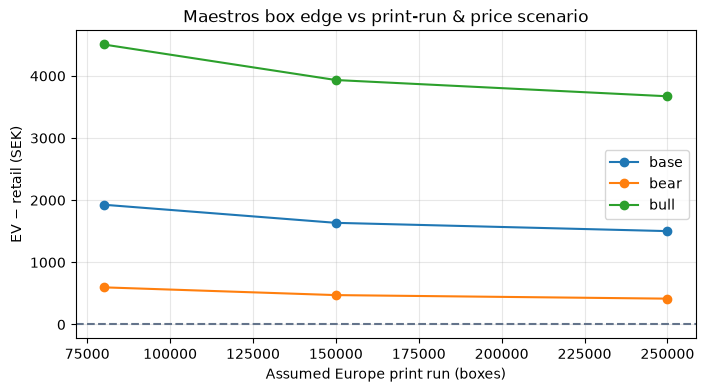

In [5]:
profit = profitability_table(RETAIL, PRINT_RUNS, product=product)
display(profit)

fig, ax = plt.subplots(figsize=(8, 4))
for scen, g in profit.groupby("price_scenario"):
    ax.plot(g["print_run_boxes"], g["edge_sek"], marker="o", label=scen)
ax.axhline(0, color="#64748b", linestyle="--")
ax.set_xlabel("Assumed Europe print run (boxes)")
ax.set_ylabel("EV − retail (SEK)")
ax.set_title("Maestros box edge vs print-run & price scenario")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 5) How P&L scales with boxes bought

Mean EV scales ~linearly. **Variance** and chance of a GMR jackpot rise with count — that is the lottery effect.

,n_boxes,cost_sek,mean_value,mean_profit,median_profit,p5_profit,p95_profit,prob_profit,mean_gmr,prob_any_gmr,mean_starlights,mean_extended
0,1.0,420.0,2019.92,1599.92,870.0,510.00,3103.50,1.0,0.01,0.01,0.31,0.86
1,3.0,1260.0,6115.37,4855.37,3725.0,1890.00,7690.00,1.0,0.03,0.03,0.95,2.54
2,6.0,2520.0,12243.01,9723.01,7830.0,4710.00,33885.00,1.0,0.07,0.07,1.93,5.07
3,12.0,5040.0,24560.41,19520.41,15985.0,10975.00,44441.00,1.0,0.14,0.14,3.84,9.95
4,24.0,10080.0,49387.12,39307.12,33070.0,25044.50,64991.00,1.0,0.29,0.25,7.71,20.11
5,36.0,15120.0,74443.63,59323.63,51025.0,39799.50,100451.25,1.0,0.45,0.36,11.52,30.21
6,60.0,25200.0,123379.87,98179.87,94330.0,69682.75,143771.00,1.0,0.72,0.51,19.31,50.14


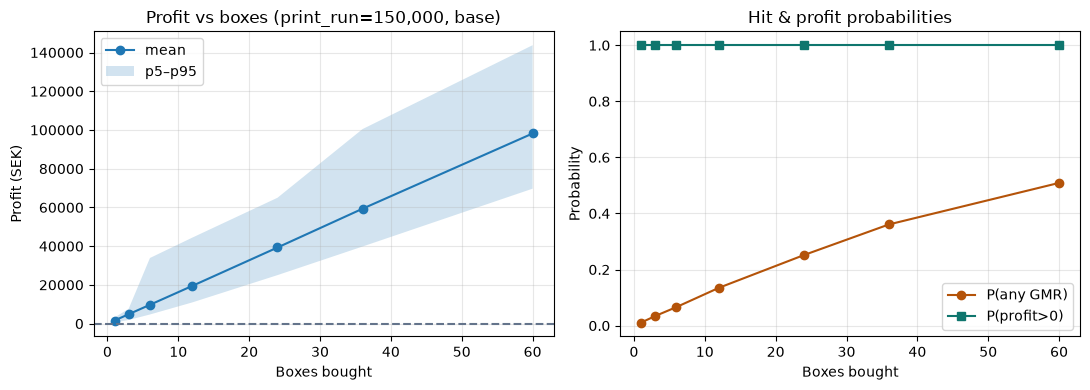

In [6]:
scale = scale_table(
    [1, 3, 6, 12, 24, 36, 60],
    print_run_boxes=BASE_RUN,
    price_scenario="base",
    retail=RETAIL,
    n_trials=4000,
    rng=np.random.default_rng(7),
    product=product,
)
display(scale.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(scale["n_boxes"], scale["mean_profit"], marker="o", label="mean")
axes[0].fill_between(scale["n_boxes"], scale["p5_profit"], scale["p95_profit"], alpha=0.2, label="p5–p95")
axes[0].axhline(0, color="#64748b", linestyle="--")
axes[0].set_xlabel("Boxes bought")
axes[0].set_ylabel("Profit (SEK)")
axes[0].set_title(f"Profit vs boxes (print_run={BASE_RUN:,}, base)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(scale["n_boxes"], scale["prob_any_gmr"], marker="o", color="#b45309", label="P(any GMR)")
axes[1].plot(scale["n_boxes"], scale["prob_profit"], marker="s", color="#0f766e", label="P(profit>0)")
axes[1].set_xlabel("Boxes bought")
axes[1].set_ylabel("Probability")
axes[1].set_title("Hit & profit probabilities")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [7]:
# Distribution at one case (12 boxes) and at 60 boxes
for n in (12, 60):
    sim = simulate_portfolio(
        n, print_run_boxes=BASE_RUN, price_scenario="base", retail=RETAIL,
        n_trials=5000, rng=np.random.default_rng(n), product=product,
    )
    print(f"\n=== {n} boxes | cost {n*RETAIL:,.0f} SEK ===")
    print(sim[["opened_value_sek", "profit_sek", "gmr_count", "starlight_count"]].describe(
        percentiles=[0.05, 0.5, 0.95]
    ).round(1))


=== 12 boxes | cost 5,040 SEK ===
       opened_value_sek  profit_sek  gmr_count  starlight_count
count            5000.0      5000.0     5000.0           5000.0
mean            24351.3     19311.3        0.1              3.8
std             10550.7     10550.7        0.4              1.9
min             12600.0      7560.0        0.0              0.0
5%              16235.0     11195.0        0.0              1.0
50%             20935.0     15895.0        0.0              4.0
95%             49415.2     44375.2        1.0              7.0
max             81700.0     76660.0        2.0             12.0



=== 60 boxes | cost 25,200 SEK ===
       opened_value_sek  profit_sek  gmr_count  starlight_count
count            5000.0      5000.0     5000.0           5000.0
mean           123302.4     98102.4        0.7             19.2
std             24407.3     24407.3        0.8              4.3
min             82265.0     57065.0        0.0              7.0
5%              94689.5     69489.5        0.0             13.0
50%            120765.0     95565.0        1.0             19.0
95%            167325.0    142125.0        2.0             27.0
max            250625.0    225425.0        5.0             36.0


## Verdict (under these assumptions)

- **Print run:** treat **~80k–250k** Europe-pool boxes as the working range; **~150k** mid.
- **GMR alone** is a bad reason to buy volume — at 150k print run, 50% any-GMR still needs ~**58 boxes** (~24k SEK at 420/box).
- **Profitability** hinges on Extended/Starlight rates and whether base singles EV clears retail **without** counting a GMR. If non-GMR EV < retail, you are buying a lottery ticket; more boxes raise jackpot odds but also raise expected loss if edge is negative.
- Prefer: buy **singles** you need; rip only if sealed is at/under break-even after fee haircut, or you explicitly want the lottery.

Re-run after Magnificent **Monsters** (Sep) community openings — that will calibrate Starlight/EA rates for this sister product.